**ENSEMBLE UPLIFT_RF_CIT + INT_RF — 5-fold CV + Full-train inference**

Notebook này train/test model **ENSEMBLE** cho bài toán DAZONE/ZaloPay theo đúng hướng uplift modeling.

**Phương pháp uplift modeling của ENSEMBLE**

Bài toán có 2 chiến lược truyền thông được phân bổ ngẫu nhiên: **Cash** và **Card**. Với mỗi khách hàng, mô hình cần ước tính tác động gia tăng/uplift khi ưu tiên truyền thông sản phẩm Cash Loan hoặc Credit Card.

Với target cash, mô hình học uplift:

`uplift_cash(x) = P(cash_sign_30d = 1 | treatment = Cash, x) - P(cash_sign_30d = 1 | treatment = Card, x)`

Với target card, mô hình học uplift:

`uplift_card(x) = P(card_sign_30d = 1 | treatment = Card, x) - P(card_sign_30d = 1 | treatment = Cash, x)`

Model **ENSEMBLE** gồm 2 nhóm base model:

- **UPLIFT_RF_CIT**: dùng Uplift Random Forest với tiêu chí CIT để trực tiếp học chênh lệch phản hồi giữa treatment và control.
- **INT_RF**: dùng Random Forest có thêm biến treatment và các tương tác `feature × treatment`, sau đó tính uplift bằng chênh lệch xác suất giữa kịch bản treatment và control.

Cách ensemble: lấy trung bình các uplift score của toàn bộ base model cho cash và card. Trong 5-fold cross-validation, mô hình được đánh giá bằng **Qini Coefficient** riêng cho cash/card, sau đó tính `qini_sum = qini_cash + qini_card`. Sau CV, notebook train lại ENSEMBLE trên toàn bộ tập train để tái tạo model cuối cùng và inference trên `test_df_feature`, xuất file `test_df_target.csv` gồm 2 cột `cash_sign_30d` và `card_sign_30d`.


In [1]:
# ============================================================
# 0. INSTALL CAUSALML BEFORE IMPORTS
# ============================================================
import sys
import subprocess

print("=" * 80)
print("CHECKING/INSTALLING DEPENDENCY: causalml==0.16.0")
print("If this cell fails on Kaggle, turn Internet ON in Notebook settings.")
print("=" * 80)

try:
    import causalml  # noqa: F401
    print("causalml is already installed.")
except Exception:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "causalml==0.16.0",
    ])
    print("causalml installed.")

print("=" * 80)
print("CAUSALML READY")
print("=" * 80)


CHECKING/INSTALLING DEPENDENCY: causalml==0.16.0
If this cell fails on Kaggle, turn Internet ON in Notebook settings.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 4.2 MB/s eta 0:00:00
causalml installed.
CAUSALML READY


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from causalml.inference.tree import UpliftRandomForestClassifier

warnings.filterwarnings("ignore")

SEED = 42
N_JOBS = 4
N_SPLITS = 5
CAUSALML_CRITERION = "CIT"

TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]

CP = Path("/kaggle/working/cp")
CP.mkdir(parents=True, exist_ok=True)

UPLIFT_RF_CIT_CONFIGS = [
    {"name": "CFG028_UPLIFT_RF_CIT", "n_estimators": 80, "max_depth": 8, "min_samples_leaf": 120, "min_samples_treatment": 20, "max_features_cap": 32},
    {"name": "CFG009_UPLIFT_RF_CIT", "n_estimators": 120, "max_depth": 5, "min_samples_leaf": 80, "min_samples_treatment": 30, "max_features_cap": 32},
    {"name": "CFG011_UPLIFT_RF_CIT", "n_estimators": 120, "max_depth": 5, "min_samples_leaf": 160, "min_samples_treatment": 40, "max_features_cap": 32},
]

INT_RF_CONFIGS = [
    {"name": "INT_RF_RS_027", "n_estimators": 560, "max_depth": 6, "min_samples_leaf": 80, "min_samples_split": 50, "max_features": "log2", "criterion": "entropy", "class_weight": "balanced", "bootstrap": True, "max_samples": None, "use_sample_weight": False, "pos_weight_multiplier": 1.0},
    {"name": "INT_RF_RS_028", "n_estimators": 420, "max_depth": 6, "min_samples_leaf": 30, "min_samples_split": 2, "max_features": "log2", "criterion": "gini", "class_weight": "balanced", "bootstrap": True, "max_samples": None, "use_sample_weight": False, "pos_weight_multiplier": 1.0},
]

ENSEMBLE_NAME = "ENSEMBLE_3_UPLIFT_RF_CIT_2_INT_RF"

print("=" * 80)
print("IMPORTS DONE")
print(f"SEED={SEED} | N_JOBS={N_JOBS} | N_SPLITS={N_SPLITS}")
print("CP:", CP)
print("TRAINING MODE: 5-fold CV, then full-train refit for test inference")
print("UPLIFT_RF_CIT_CONFIGS:")
for cfg in UPLIFT_RF_CIT_CONFIGS:
    print(" ", cfg)
print("INT_RF_CONFIGS:")
for cfg in INT_RF_CONFIGS:
    print(" ", cfg)
print("ENSEMBLE:", ENSEMBLE_NAME)
print("=" * 80)


Failed to import duecredit due to No module named 'duecredit'


IMPORTS DONE
SEED=42 | N_JOBS=4 | N_SPLITS=5
CP: /kaggle/working/cp
TRAINING MODE: 5-fold CV, then full-train refit for test inference
UPLIFT_RF_CIT_CONFIGS:
  {'name': 'CFG028_UPLIFT_RF_CIT', 'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 120, 'min_samples_treatment': 20, 'max_features_cap': 32}
  {'name': 'CFG009_UPLIFT_RF_CIT', 'n_estimators': 120, 'max_depth': 5, 'min_samples_leaf': 80, 'min_samples_treatment': 30, 'max_features_cap': 32}
  {'name': 'CFG011_UPLIFT_RF_CIT', 'n_estimators': 120, 'max_depth': 5, 'min_samples_leaf': 160, 'min_samples_treatment': 40, 'max_features_cap': 32}
INT_RF_CONFIGS:
  {'name': 'INT_RF_RS_027', 'n_estimators': 560, 'max_depth': 6, 'min_samples_leaf': 80, 'min_samples_split': 50, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': 'balanced', 'bootstrap': True, 'max_samples': None, 'use_sample_weight': False, 'pos_weight_multiplier': 1.0}
  {'name': 'INT_RF_RS_028', 'n_estimators': 420, 'max_depth': 6, 'min_samples_leaf': 30, '

In [3]:
# ============================================================
# 2. LOAD TRAIN/TEST CSV
# ============================================================
# Điền path csv tại đây khi chạy trên Kaggle.

df_feature_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
df_target_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"
test_df_feature_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/test_df_feature.csv"

df_feature = pd.read_csv(df_feature_path)
df_target = pd.read_csv(df_target_path)
test_df_feature = pd.read_csv(test_df_feature_path)

print("=" * 80)
print("DATA LOADED")
print(f"df_feature       : {df_feature.shape}")
print(f"df_target        : {df_target.shape}")
print(f"test_df_feature  : {test_df_feature.shape}")
print("CP:", CP)
print("=" * 80)


DATA LOADED
df_feature       : (136992, 63)
df_target        : (136992, 2)
test_df_feature  : (34080, 63)
CP: /kaggle/working/cp


In [4]:
# ============================================================
# 3. FEATURE PREPARATION HELPERS
# ============================================================
FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# None -> baseline, không drop feature nào.
COL_IDX = None


def normalize_feature_drop_selection(selection):
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                return list(range(int(m.group(1)), int(m.group(2))))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError("COL_IDX không hợp lệ.")

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
        else:
            base_col = str(item).strip()
            idx = FEATURE_DROP_PRIORITY_LIST.index(base_col) if base_col in FEATURE_DROP_PRIORITY_LIST else None
            if idx is None:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong feature.")

        if base_col not in seen_cols:
            drop_ids.append(idx)
            drop_base_cols.append(base_col)
            seen_cols.add(base_col)

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df, target_df=None):
    source_df = feature_df
    source_name = "feature"

    if TREAT_COL_BINARY not in source_df.columns and TREAT_COL_RAW not in source_df.columns and target_df is not None:
        source_df = target_df
        source_name = "target"

    if TREAT_COL_BINARY in source_df.columns:
        return source_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY, source_name

    if TREAT_COL_RAW not in source_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong feature/target.")

    s = source_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        vals = s.astype(int).to_numpy()
        unique_vals = set(pd.Series(vals).dropna().unique())
        if unique_vals <= {0, 1}:
            return vals, TREAT_COL_RAW, source_name
        raise ValueError(f"Cột treatment dạng số nhưng không phải binary 0/1. Unique mẫu: {sorted(list(unique_vals))[:10]}")

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")

    return mapped.astype(int), TREAT_COL_RAW, source_name


def get_feature_columns(train_feature_df, test_feature_df=None):
    feature_drop_idxs, feature_drop_base_cols = normalize_feature_drop_selection(COL_IDX)

    drop_cols = []
    for base_col in feature_drop_base_cols:
        drop_cols.extend(match_base_feature_columns(train_feature_df.columns, base_col))
    drop_cols = list(dict.fromkeys(drop_cols))

    train_id_col = next((col for col in ID_CANDIDATES if col in train_feature_df.columns), None)
    test_id_col = None
    if test_feature_df is not None:
        test_id_col = next((col for col in ID_CANDIDATES if col in test_feature_df.columns), None)

    index_like_cols = [c for c in train_feature_df.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
    exclude_cols = set(drop_cols + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
    if train_id_col is not None:
        exclude_cols.add(train_id_col)

    feat_cols = [col for col in train_feature_df.columns if col not in exclude_cols]
    return feat_cols, drop_cols, feature_drop_idxs, feature_drop_base_cols, train_id_col, test_id_col


def make_design_matrices(fit_feature_df, transform_feature_dfs, feat_cols):
    """
    Fit preprocessing on fit_feature_df, then transform validation/test frames.
    - Numeric columns: median imputation.
    - Categorical/object columns: one-hot encoding, aligned to training dummies.
    """
    fit_raw = fit_feature_df.reindex(columns=feat_cols, fill_value=0).copy()
    transform_raws = [df.reindex(columns=feat_cols, fill_value=0).copy() for df in transform_feature_dfs]

    cat_cols = fit_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    num_cols = [c for c in fit_raw.columns if c not in cat_cols]

    if num_cols:
        fit_num = fit_raw[num_cols].apply(pd.to_numeric, errors="coerce")
        med = fit_num.median(axis=0).fillna(0)
        fit_num = fit_num.fillna(med)

        transformed_nums = []
        for raw in transform_raws:
            tnum = raw[num_cols].apply(pd.to_numeric, errors="coerce").fillna(med)
            transformed_nums.append(tnum)
    else:
        fit_num = pd.DataFrame(index=fit_raw.index)
        transformed_nums = [pd.DataFrame(index=raw.index) for raw in transform_raws]

    if cat_cols:
        fit_cat = pd.get_dummies(fit_raw[cat_cols].astype("object").fillna("__MISSING__"), dummy_na=False)
        transformed_cats = []
        for raw in transform_raws:
            tcat = pd.get_dummies(raw[cat_cols].astype("object").fillna("__MISSING__"), dummy_na=False)
            tcat = tcat.reindex(columns=fit_cat.columns, fill_value=0)
            transformed_cats.append(tcat)
    else:
        fit_cat = pd.DataFrame(index=fit_raw.index)
        transformed_cats = [pd.DataFrame(index=raw.index) for raw in transform_raws]

    X_fit_df = pd.concat([fit_num.reset_index(drop=True), fit_cat.reset_index(drop=True)], axis=1)
    X_fit = X_fit_df.to_numpy(dtype=np.float32)

    X_transforms = []
    for tnum, tcat in zip(transformed_nums, transformed_cats):
        X_df = pd.concat([tnum.reset_index(drop=True), tcat.reset_index(drop=True)], axis=1)
        X_df = X_df.reindex(columns=X_fit_df.columns, fill_value=0)
        X_transforms.append(X_df.to_numpy(dtype=np.float32))

    return X_fit, X_transforms, X_fit_df.columns.tolist()


assert len(df_feature) == len(df_target), "df_feature và df_target khác số dòng."
for col in [TARGET_CASH, TARGET_CARD]:
    assert col in df_target.columns, f"Thiếu target column: {col}"

W_all, TREAT_COL_TRAIN, TREAT_SOURCE_TRAIN = encode_treatment_cash(df_feature, df_target)
Y_cash_all = df_target[TARGET_CASH].astype(int).to_numpy()
Y_card_all = df_target[TARGET_CARD].astype(int).to_numpy()

FEAT_COLS, DROP_COLS_IN_TRAIN, FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS, train_id_col, test_id_col = get_feature_columns(df_feature, test_df_feature)
train_id = make_id_series(df_feature, id_col=train_id_col)
test_id = make_id_series(test_df_feature, id_col=test_id_col)

FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if train_id_col is not None:
    FORBIDDEN_FEATURE_COLS.add(train_id_col)
forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(df_feature.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(df_feature.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})
feature_drop_audit.to_csv(CP / "feature_drop_audit.csv", index=False)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped train feature columns ({len(DROP_COLS_IN_TRAIN)}): {DROP_COLS_IN_TRAIN}")
print("=" * 80)
print(f"Train N={len(df_feature):,} | Test N={len(test_df_feature):,} | raw feature columns={len(FEAT_COLS):,}")
print(f"Train treatment source: {TREAT_SOURCE_TRAIN}.{TREAT_COL_TRAIN}")
print(f"Train Treatment Cash: {W_all.sum():,} ({W_all.mean():.2%}) | Card: {(1-W_all).sum():,} ({(1-W_all).mean():.2%})")
print(f"Train cash target rate: {Y_cash_all.mean():.4%} | Train card target rate: {Y_card_all.mean():.4%}")
print("Saved:", CP / "feature_drop_audit.csv")
print("=" * 80)
display(feature_drop_audit)


FEATURE DROPPING: baseline, không drop feature nào
Train N=136,992 | Test N=34,080 | raw feature columns=62
Train treatment source: feature.treatment_cash
Train Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Train cash target rate: 5.9186% | Train card target rate: 2.7111%
Saved: /kaggle/working/cp/feature_drop_audit.csv


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


In [5]:

# ============================================================
# 4. QINI METRIC + PLOT
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def save_qini_plot(target_name, y, w_event, score, fold_idx, output_path):
    from matplotlib.ticker import PercentFormatter

    x_model, q_model = qini_curve(y, w_event, score)
    met = qini_metrics(y, w_event, score)
    ate = q_model[-1]
    baseline = ate * x_model

    if str(target_name).lower() == "cash":
        plot_title = "Cash Uplift Model — Qini Curve"
    else:
        plot_title = "Card Uplift Model — Qini Curve"

    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("#EAEAF2")

    ax.plot(
        x_model,
        q_model,
        color="#1f77b4",
        linewidth=2.0,
        label=f"Model  |  Qini={met['qini_norm']:.6f}",
        zorder=3,
    )
    ax.plot(
        [0, 1],
        [0, ate],
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label="Random baseline",
        zorder=2,
    )

    ax.fill_between(
        x_model,
        q_model,
        baseline,
        where=(q_model >= baseline),
        interpolate=True,
        alpha=0.18,
        color="#4C78A8",
        zorder=1,
    )
    ax.fill_between(
        x_model,
        q_model,
        baseline,
        where=(q_model < baseline),
        interpolate=True,
        alpha=0.12,
        color="#D62728",
        zorder=1,
    )

    ax.set_title(plot_title, fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Fraction of Population Targeted", fontsize=11)
    ax.set_ylabel("Incremental Gain (rate)", fontsize=11)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(True, color="white", linewidth=1.0, alpha=0.7)
    ax.legend(loc="upper left", fontsize=9, frameon=True, framealpha=0.95)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_alpha(0.3)
    ax.spines["bottom"].set_alpha(0.3)

    plt.tight_layout()
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved styled Qini curve for {target_name} | best fold={fold_idx} -> {output_path}")


print("QINI FUNCTIONS READY")


QINI FUNCTIONS READY


In [6]:
# ============================================================
# 5. UPLIFT_RF_CIT HELPERS
# ============================================================
def get_treatment_labels(w_event):
    return np.where(np.asarray(w_event) == 1, "treatment", "control")


def make_causalml_rf(params, seed, n_features):
    max_features = int(max(1, min(int(params["max_features_cap"]), n_features)))
    base_kwargs = dict(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        min_samples_treatment=params["min_samples_treatment"],
        max_features=max_features,
        evaluationFunction=CAUSALML_CRITERION,
        control_name="control",
    )

    for extra_kwargs in [{"n_jobs": N_JOBS, "random_state": seed}, {"random_state": seed}, {"n_jobs": N_JOBS}, {}]:
        try:
            return UpliftRandomForestClassifier(**base_kwargs, **extra_kwargs)
        except TypeError:
            continue

    return UpliftRandomForestClassifier(**base_kwargs)


def extract_uplift_prediction(pred_raw):
    if isinstance(pred_raw, pd.DataFrame):
        num = pred_raw.select_dtypes(include=[np.number])
        for c in ["uplift", "treatment_effect", "maxTreatmentEffect", "recommended_treatment_effect"]:
            if c in num.columns:
                return num[c].to_numpy(dtype=float)
        return num.iloc[:, -1].to_numpy(dtype=float)

    arr = np.asarray(pred_raw)
    if arr.ndim == 1:
        return arr.astype(float)
    if arr.ndim >= 2 and arr.shape[1] >= 2:
        return (arr[:, 1] - arr[:, 0]).astype(float)
    return arr[:, 0].astype(float)


def train_predict_uplift_rf_cit(params, target_name, X_fit, y_fit, w_event_fit, X_pred):
    target_offset = 101 if target_name == "cash" else 202
    model_seed = SEED + target_offset + int(params["n_estimators"])
    model = make_causalml_rf(params=params, seed=model_seed, n_features=X_fit.shape[1])

    treatment_labels_fit = get_treatment_labels(w_event_fit)
    model.fit(X_fit, treatment=treatment_labels_fit, y=y_fit)

    uplift_pred = extract_uplift_prediction(model.predict(X_pred))

    # CausalML Uplift RF trả về uplift score. Để xuất xác suất cho test,
    # dùng control base-rate trên tập fit rồi cộng uplift, sau đó clip về [0, 1].
    control_mask = np.asarray(w_event_fit) == 0
    control_rate = float(np.mean(y_fit[control_mask])) if control_mask.sum() > 0 else float(np.mean(y_fit))
    prob_event = np.clip(control_rate + uplift_pred, 0.0, 1.0)

    return {
        "model": model,
        "uplift": uplift_pred.astype(float),
        "prob_event": prob_event.astype(float),
        "seed": model_seed,
    }


print("UPLIFT_RF_CIT HELPERS READY")


UPLIFT_RF_CIT HELPERS READY


In [7]:
# ============================================================
# 6. INT_RF HELPERS
# ============================================================
class ConstantClassifier:
    def __init__(self, value):
        self.value = float(value)
        self.classes_ = np.array([0, 1])

    def fit(self, X, y, sample_weight=None):
        return self

    def predict_proba(self, X):
        p = np.full(len(X), self.value, dtype=float)
        p = np.clip(p, 0.0, 1.0)
        return np.c_[1 - p, p]


def make_rf_classifier(params, seed=SEED):
    return RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        min_samples_split=params["min_samples_split"],
        max_features=params["max_features"],
        criterion=params["criterion"],
        class_weight=params["class_weight"],
        bootstrap=params["bootstrap"],
        max_samples=params["max_samples"],
        n_jobs=N_JOBS,
        random_state=seed,
    )


def class_weights(y, pos_weight_multiplier=1.0):
    y = np.asarray(y, dtype=int)
    pos = max(int(y.sum()), 1)
    neg = max(len(y) - pos, 1)
    pos_weight = (neg / pos) * float(pos_weight_multiplier)
    return np.where(y == 1, pos_weight, 1.0).astype(np.float32)


def fit_classifier(X_fit, y_fit, params, seed=SEED):
    y_fit = np.asarray(y_fit, dtype=int)
    if len(y_fit) == 0 or len(np.unique(y_fit)) < 2:
        return ConstantClassifier(float(y_fit.mean()) if len(y_fit) else 0.0)

    model = make_rf_classifier(params=params, seed=seed)
    sample_weight = class_weights(y_fit, params["pos_weight_multiplier"]) if params["use_sample_weight"] else None
    model.fit(X_fit, y_fit, sample_weight=sample_weight)
    return model


def predict_classifier(model, X_pred):
    proba = np.asarray(model.predict_proba(X_pred))
    if proba.ndim == 1:
        return np.clip(proba.astype(float), 0.0, 1.0)
    if proba.shape[1] == 1:
        classes = getattr(model, "classes_", np.array([1]))
        return np.full(len(X_pred), float(classes[0] == 1))
    classes = list(getattr(model, "classes_", [0, 1]))
    idx = classes.index(1) if 1 in classes else -1
    return proba[:, idx].astype(float)


def make_interaction_matrix(X_base, w_event):
    w_col = np.asarray(w_event, dtype=np.float32)[:, None]
    return np.c_[X_base, w_col, X_base * w_col]


def make_event_control_matrices(X_base):
    n = len(X_base)
    X_event = np.c_[X_base, np.ones((n, 1), dtype=np.float32), X_base]
    X_control = np.c_[X_base, np.zeros((n, 1), dtype=np.float32), np.zeros_like(X_base)]
    return X_event, X_control


def train_predict_int_rf(params, target_name, X_fit, y_fit, w_event_fit, X_pred):
    seed_offset = 303 if target_name == "cash" else 404
    model_seed = SEED + seed_offset + int(params["n_estimators"])

    X_aug_fit = make_interaction_matrix(X_fit, w_event_fit)
    model = fit_classifier(X_aug_fit, y_fit, params=params, seed=model_seed)

    X_pred_event, X_pred_control = make_event_control_matrices(X_pred)
    p_event = predict_classifier(model, X_pred_event)
    p_control = predict_classifier(model, X_pred_control)
    uplift_pred = p_event - p_control

    return {
        "model": model,
        "uplift": uplift_pred.astype(float),
        "prob_event": np.clip(p_event, 0.0, 1.0).astype(float),
        "seed": model_seed,
    }


print("INT_RF HELPERS READY")


INT_RF HELPERS READY


In [8]:
# ============================================================
# 7. ENSEMBLE TRAIN/PREDICT FUNCTION
# ============================================================
def train_ensemble_predict(X_fit, y_cash_fit, y_card_fit, W_fit, X_pred, phase_label=""):
    """
    Return:
    - uplift_cash/uplift_card: dùng để tính Qini.
    - prob_cash/prob_card: dùng để xuất test_df_target.
    """
    pred_store = {
        "cash": {"uplift": {}, "prob_event": {}},
        "card": {"uplift": {}, "prob_event": {}},
    }
    model_store = {}
    log_rows = []

    targets = {
        "cash": {
            "y": np.asarray(y_cash_fit, dtype=int),
            "w_event": (np.asarray(W_fit) == 1).astype(int),  # Cash là treatment event
            "family_label": "CASH",
        },
        "card": {
            "y": np.asarray(y_card_fit, dtype=int),
            "w_event": (np.asarray(W_fit) == 0).astype(int),  # Card là treatment event
            "family_label": "CARD",
        },
    }

    t_all = time.time()

    for cfg in UPLIFT_RF_CIT_CONFIGS:
        model_store[cfg["name"]] = {}
        print("\n" + "=" * 80)
        print(f"{phase_label} START {cfg['name']}")
        print(cfg)
        print("=" * 80)

        for target_name, info in targets.items():
            t0 = time.time()
            out = train_predict_uplift_rf_cit(
                params=cfg,
                target_name=target_name,
                X_fit=X_fit,
                y_fit=info["y"],
                w_event_fit=info["w_event"],
                X_pred=X_pred,
            )
            pred_store[target_name]["uplift"][cfg["name"]] = out["uplift"]
            pred_store[target_name]["prob_event"][cfg["name"]] = out["prob_event"]
            model_store[cfg["name"]][target_name] = out["model"]
            log_rows.append({
                "phase": phase_label,
                "model": cfg["name"],
                "model_family": "UPLIFT_RF_CIT",
                "target": target_name,
                "seed": out["seed"],
                "minutes": (time.time() - t0) / 60,
            })
            print(f"{phase_label} finished {cfg['name']} target={target_name.upper()} | minutes={(time.time() - t0) / 60:.4f}")
            gc.collect()

    for cfg in INT_RF_CONFIGS:
        model_store[cfg["name"]] = {}
        print("\n" + "=" * 80)
        print(f"{phase_label} START {cfg['name']}")
        print(cfg)
        print("=" * 80)

        for target_name, info in targets.items():
            t0 = time.time()
            out = train_predict_int_rf(
                params=cfg,
                target_name=target_name,
                X_fit=X_fit,
                y_fit=info["y"],
                w_event_fit=info["w_event"],
                X_pred=X_pred,
            )
            pred_store[target_name]["uplift"][cfg["name"]] = out["uplift"]
            pred_store[target_name]["prob_event"][cfg["name"]] = out["prob_event"]
            model_store[cfg["name"]][target_name] = out["model"]
            log_rows.append({
                "phase": phase_label,
                "model": cfg["name"],
                "model_family": "INT_RF",
                "target": target_name,
                "seed": out["seed"],
                "minutes": (time.time() - t0) / 60,
            })
            print(f"{phase_label} finished {cfg['name']} target={target_name.upper()} | minutes={(time.time() - t0) / 60:.4f}")
            gc.collect()

    base_model_names = list(pred_store["cash"]["uplift"].keys())

    def avg(target_name, key):
        return np.mean(
            np.column_stack([np.asarray(pred_store[target_name][key][name], dtype=float) for name in base_model_names]),
            axis=1,
        )

    result = {
        "uplift_cash": avg("cash", "uplift"),
        "uplift_card": avg("card", "uplift"),
        "prob_cash": np.clip(avg("cash", "prob_event"), 0.0, 1.0),
        "prob_card": np.clip(avg("card", "prob_event"), 0.0, 1.0),
        "base_model_names": base_model_names,
        "base_predictions": pred_store,
        "models": model_store,
        "log_rows": log_rows,
        "minutes_total": (time.time() - t_all) / 60,
    }

    print("\n" + "=" * 80)
    print(f"{phase_label} ENSEMBLE DONE | minutes_total={result['minutes_total']:.4f}")
    print("Base models:", base_model_names)
    print("=" * 80)

    return result


print("ENSEMBLE FUNCTION READY")


ENSEMBLE FUNCTION READY


In [9]:
# ============================================================
# 8. 5-FOLD CROSS VALIDATION ON df_feature + df_target
# ============================================================
def make_cv_splits(df_feature, df_target, W_all):
    # Ưu tiên stratify theo treatment + 2 target để fold ổn định hơn.
    y_strat = (
        pd.Series(W_all).astype(str)
        + "_"
        + df_target[TARGET_CASH].astype(str)
        + "_"
        + df_target[TARGET_CARD].astype(str)
    )
    counts = y_strat.value_counts()
    if counts.min() >= N_SPLITS:
        splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
        return list(splitter.split(df_feature, y_strat))

    print("WARNING: Một vài strata có số mẫu < N_SPLITS. Fallback sang StratifiedKFold theo treatment.")
    y_treat = pd.Series(W_all).astype(str)
    if y_treat.value_counts().min() >= N_SPLITS:
        splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
        return list(splitter.split(df_feature, y_treat))

    print("WARNING: Treatment strata cũng quá nhỏ. Fallback sang KFold.")
    splitter = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    return list(splitter.split(df_feature))


cv_splits = make_cv_splits(df_feature, df_target, W_all)

cv_rows = []
cv_run_logs = []
best_fold = None
best_fold_payload = None

print("=" * 80)
print("START 5-FOLD CROSS VALIDATION")
print("=" * 80)

for fold_idx, (tr_idx, va_idx) in enumerate(cv_splits):
    print("\n" + "#" * 80)
    print(f"FOLD {fold_idx}/{N_SPLITS - 1} | train={len(tr_idx):,} | valid={len(va_idx):,}")
    print("#" * 80)

    fold_train_feature = df_feature.iloc[tr_idx].reset_index(drop=True)
    fold_valid_feature = df_feature.iloc[va_idx].reset_index(drop=True)

    X_tr, [X_va], encoded_cols = make_design_matrices(
        fit_feature_df=fold_train_feature,
        transform_feature_dfs=[fold_valid_feature],
        feat_cols=FEAT_COLS,
    )

    y_cash_tr = Y_cash_all[tr_idx]
    y_card_tr = Y_card_all[tr_idx]
    W_tr = W_all[tr_idx]

    y_cash_va = Y_cash_all[va_idx]
    y_card_va = Y_card_all[va_idx]
    W_va = W_all[va_idx]
    w_cash_va = (W_va == 1).astype(int)
    w_card_va = (W_va == 0).astype(int)

    fold_pred = train_ensemble_predict(
        X_fit=X_tr,
        y_cash_fit=y_cash_tr,
        y_card_fit=y_card_tr,
        W_fit=W_tr,
        X_pred=X_va,
        phase_label=f"fold_{fold_idx}",
    )

    cash_met = qini_metrics(y_cash_va, w_cash_va, fold_pred["uplift_cash"])
    card_met = qini_metrics(y_card_va, w_card_va, fold_pred["uplift_card"])
    qini_cash = cash_met["qini_norm"]
    qini_card = card_met["qini_norm"]
    qini_sum = qini_cash + qini_card

    row = {
        "part": fold_idx,
        "qini_cash": qini_cash,
        "qini_card": qini_card,
        "qini_sum": qini_sum,
    }
    cv_rows.append(row)

    for log_row in fold_pred["log_rows"]:
        log_row = dict(log_row)
        log_row["part"] = fold_idx
        cv_run_logs.append(log_row)

    print("\n" + "=" * 80)
    print(f"FOLD {fold_idx} RESULT")
    print(pd.DataFrame([row]).round(6).to_string(index=False))
    print("=" * 80)

    if best_fold is None or qini_sum > best_fold["qini_sum"]:
        best_fold = dict(row)
        best_fold_payload = {
            "fold_idx": fold_idx,
            "valid_idx": va_idx,
            "y_cash": y_cash_va.copy(),
            "y_card": y_card_va.copy(),
            "w_cash": w_cash_va.copy(),
            "w_card": w_card_va.copy(),
            "uplift_cash": fold_pred["uplift_cash"].copy(),
            "uplift_card": fold_pred["uplift_card"].copy(),
        }

    del X_tr, X_va, fold_pred
    gc.collect()

cv_summary = pd.DataFrame(cv_rows)
mean_row = {
    "part": "mean_5_fold",
    "qini_cash": cv_summary["qini_cash"].mean(),
    "qini_card": cv_summary["qini_card"].mean(),
    "qini_sum": cv_summary["qini_sum"].mean(),
}
cv_summary = pd.concat([cv_summary, pd.DataFrame([mean_row])], ignore_index=True)

cv_summary_path = CP / "cv_qini_summary.csv"
cv_run_log_path = CP / "cv_run_log.csv"
cv_summary.to_csv(cv_summary_path, index=False)
pd.DataFrame(cv_run_logs).to_csv(cv_run_log_path, index=False)

print("\n" + "=" * 80)
print("5-FOLD CV SUMMARY")
print(cv_summary.round(6).to_string(index=False))
print("=" * 80)
print("BEST FOLD BY qini_sum:")
print(pd.DataFrame([best_fold]).round(6).to_string(index=False))
print("Saved:", cv_summary_path)
print("Saved:", cv_run_log_path)
print("=" * 80)

display(cv_summary.round(6))


START 5-FOLD CROSS VALIDATION

################################################################################
FOLD 0/4 | train=109,593 | valid=27,399
################################################################################

fold_0 START CFG028_UPLIFT_RF_CIT
{'name': 'CFG028_UPLIFT_RF_CIT', 'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 120, 'min_samples_treatment': 20, 'max_features_cap': 32}
fold_0 finished CFG028_UPLIFT_RF_CIT target=CASH | minutes=6.5111
fold_0 finished CFG028_UPLIFT_RF_CIT target=CARD | minutes=6.1313

fold_0 START CFG009_UPLIFT_RF_CIT
{'name': 'CFG009_UPLIFT_RF_CIT', 'n_estimators': 120, 'max_depth': 5, 'min_samples_leaf': 80, 'min_samples_treatment': 30, 'max_features_cap': 32}
fold_0 finished CFG009_UPLIFT_RF_CIT target=CASH | minutes=2.6764
fold_0 finished CFG009_UPLIFT_RF_CIT target=CARD | minutes=2.7740

fold_0 START CFG011_UPLIFT_RF_CIT
{'name': 'CFG011_UPLIFT_RF_CIT', 'n_estimators': 120, 'max_depth': 5, 'min_samples_leaf': 160, 'min_samp

,part,qini_cash,qini_card,qini_sum
0,0,0.054649,0.034239,0.088888
1,1,0.060871,0.071237,0.132108
2,2,0.053167,0.036965,0.090131
3,3,0.053593,0.023256,0.076850
4,4,0.065876,0.020799,0.086675
5,mean_5_fold,0.057631,0.037299,0.094930


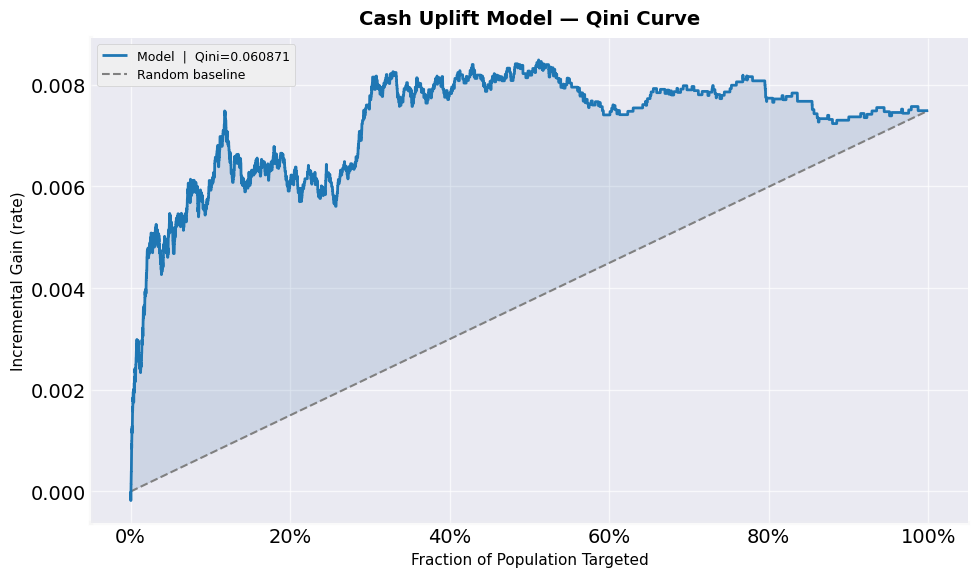

Saved styled Qini curve for cash | best fold=1 -> /kaggle/working/cp/qini_curve_cash_best_fold.png


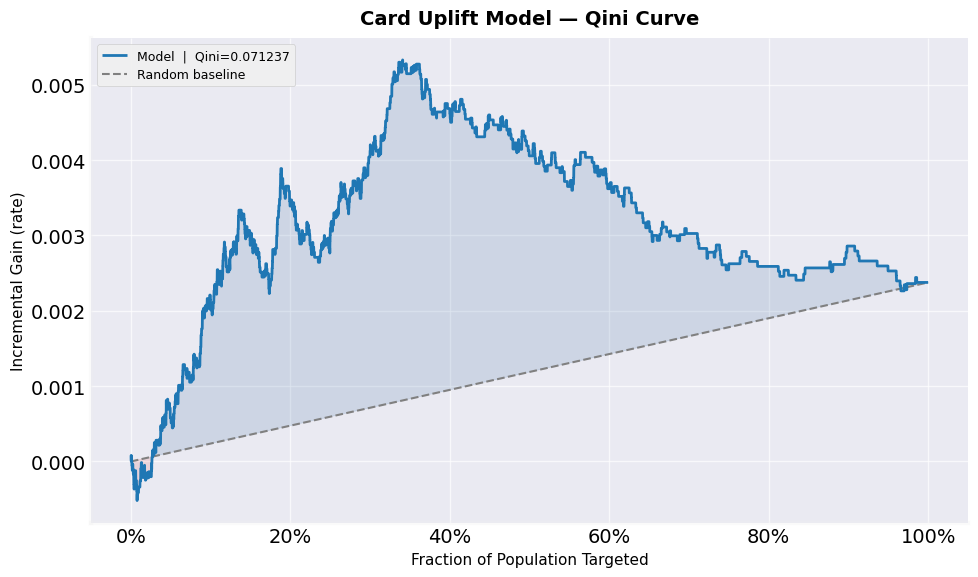

Saved styled Qini curve for card | best fold=1 -> /kaggle/working/cp/qini_curve_card_best_fold.png
BEST-FOLD QINI CURVES SAVED
cash: /kaggle/working/cp/qini_curve_cash_best_fold.png
card: /kaggle/working/cp/qini_curve_card_best_fold.png


In [10]:
# ============================================================
# 9. SAVE QINI CURVES FOR BEST VALIDATION FOLD
# ============================================================
best_fold_idx = int(best_fold_payload["fold_idx"])

cash_curve_path = CP / "qini_curve_cash_best_fold.png"
card_curve_path = CP / "qini_curve_card_best_fold.png"

save_qini_plot(
    target_name="cash",
    y=best_fold_payload["y_cash"],
    w_event=best_fold_payload["w_cash"],
    score=best_fold_payload["uplift_cash"],
    fold_idx=best_fold_idx,
    output_path=cash_curve_path,
)

save_qini_plot(
    target_name="card",
    y=best_fold_payload["y_card"],
    w_event=best_fold_payload["w_card"],
    score=best_fold_payload["uplift_card"],
    fold_idx=best_fold_idx,
    output_path=card_curve_path,
)

print("=" * 80)
print("BEST-FOLD QINI CURVES SAVED")
print("cash:", cash_curve_path)
print("card:", card_curve_path)
print("=" * 80)
